In [2]:
import json
from pathlib import Path

root = Path("../data/msd/Task01_BrainTumour")
meta = json.loads((root / "dataset.json").read_text())

print("Modalities:", meta["modality"])
print("Labels:", meta["labels"])
print("Training cases:", meta["numTraining"])
print("First entry:", meta["training"][0])

Modalities: {'0': 'FLAIR', '1': 'T1w', '2': 't1gd', '3': 'T2w'}
Labels: {'0': 'background', '1': 'edema', '2': 'non-enhancing tumor', '3': 'enhancing tumour'}
Training cases: 484
First entry: {'image': './imagesTr/BRATS_457.nii.gz', 'label': './labelsTr/BRATS_457.nii.gz'}


In [3]:
import nibabel as nib
import numpy as np

case = meta["training"][0]
img = nib.load(root / case["image"])
lbl = nib.load(root / case["label"])

print("Image shape:", img.shape)
print("Voxel size (mm):", img.header.get_zooms())
print("Label shape:", lbl.shape)
print("Label values:", np.unique(np.asarray(lbl.dataobj)))
print("Affine:\n", img.affine)

Image shape: (240, 240, 155, 4)
Voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0))
Label shape: (240, 240, 155)
Label values: [0 1 2 3]
Affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


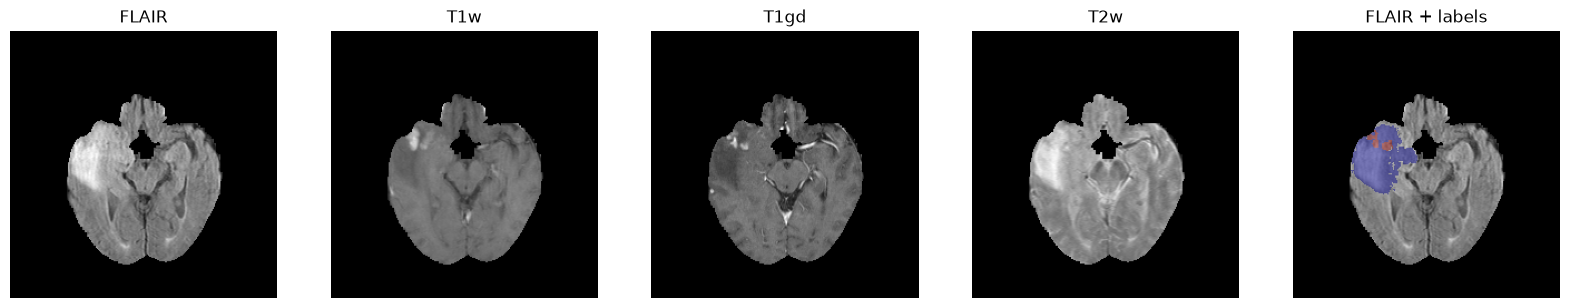

In [4]:
import matplotlib.pyplot as plt

x = np.asarray(img.dataobj, dtype=np.float32)
y = np.asarray(lbl.dataobj).astype(np.uint8)

z = int(np.argmax((y > 0).sum(axis=(0, 1))))  # slice with the most tumour

names = ["FLAIR", "T1w", "T1gd", "T2w"]
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for i in range(4):
    ax[i].imshow(x[:, :, z, i].T, cmap="gray", origin="lower")
    ax[i].set_title(names[i])
ax[4].imshow(x[:, :, z, 0].T, cmap="gray", origin="lower")
ax[4].imshow(np.ma.masked_equal(y[:, :, z], 0).T, cmap="jet", alpha=0.5, origin="lower", vmin=1, vmax=3)
ax[4].set_title("FLAIR + labels")
for a in ax:
    a.axis("off")
plt.show()

In [5]:
wt = np.isin(y, [1, 2, 3])
tc = np.isin(y, [2, 3])
et = (y == 3)

for name, m in [("Whole tumour", wt), ("Tumour core", tc), ("Enhancing", et)]:
    print(f"{name:13s}: {m.sum():7d} voxels = {m.sum() / 1000:6.1f} mL")

print("Tumour share of the brain:", round(wt.sum() / (x[..., 0] > 0).sum() * 100, 1), "%")

Whole tumour :   73791 voxels =   73.8 mL
Tumour core  :    3265 voxels =    3.3 mL
Enhancing    :    3218 voxels =    3.2 mL
Tumour share of the brain: 4.9 %


In [6]:
# Which label is brightest on the contrast scan (T1gd)? That one is the enhancing tumour.
stats = {1: [], 2: [], 3: []}
for c in meta["training"][:30]:
    x = np.asarray(nib.load(root / c["image"]).dataobj, dtype=np.float32)
    y = np.asarray(nib.load(root / c["label"]).dataobj).astype(np.uint8)
    brain = x[..., 0] > 0
    t1gd = x[..., 2]
    z = (t1gd - t1gd[brain].mean()) / t1gd[brain].std()   # brightness relative to this brain
    for lab in (1, 2, 3):
        if (y == lab).any():
            stats[lab].append(float(z[y == lab].mean()))

for lab, vals in stats.items():
    print(f"label {lab}: mean T1gd brightness {np.mean(vals):+.2f}  (in {len(vals)} of 30 cases)")

label 1: mean T1gd brightness -0.09  (in 30 of 30 cases)
label 2: mean T1gd brightness -0.25  (in 30 of 30 cases)
label 3: mean T1gd brightness +2.12  (in 30 of 30 cases)
